In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import pandas as pd

df = pd.read_csv("/content/drive/MyDrive/mean log2(TPM+1) of 52 GEJA Models vs mean log2(TPM+1) of 1,667 Not GEJA Models (1).csv")


df = df.rename(columns={
    "mean log2(TPM+1) of 52 GEJA Models Expression (Short-read) Public 26Q1": "GEJA",
    "mean log2(TPM+1) of 1,667 Not GEJA Models Expression (Short-read) Public 26Q1": "Not_GEJA"
})

   Gene      GEJA  Not_GEJA
0  A1BG  1.300474  2.440034
1  NAT2  0.454906  0.218503
2   ADA  3.228743  3.480131
3  CDH2  1.358505  3.216066
4  AKT3  2.152075  3.486312


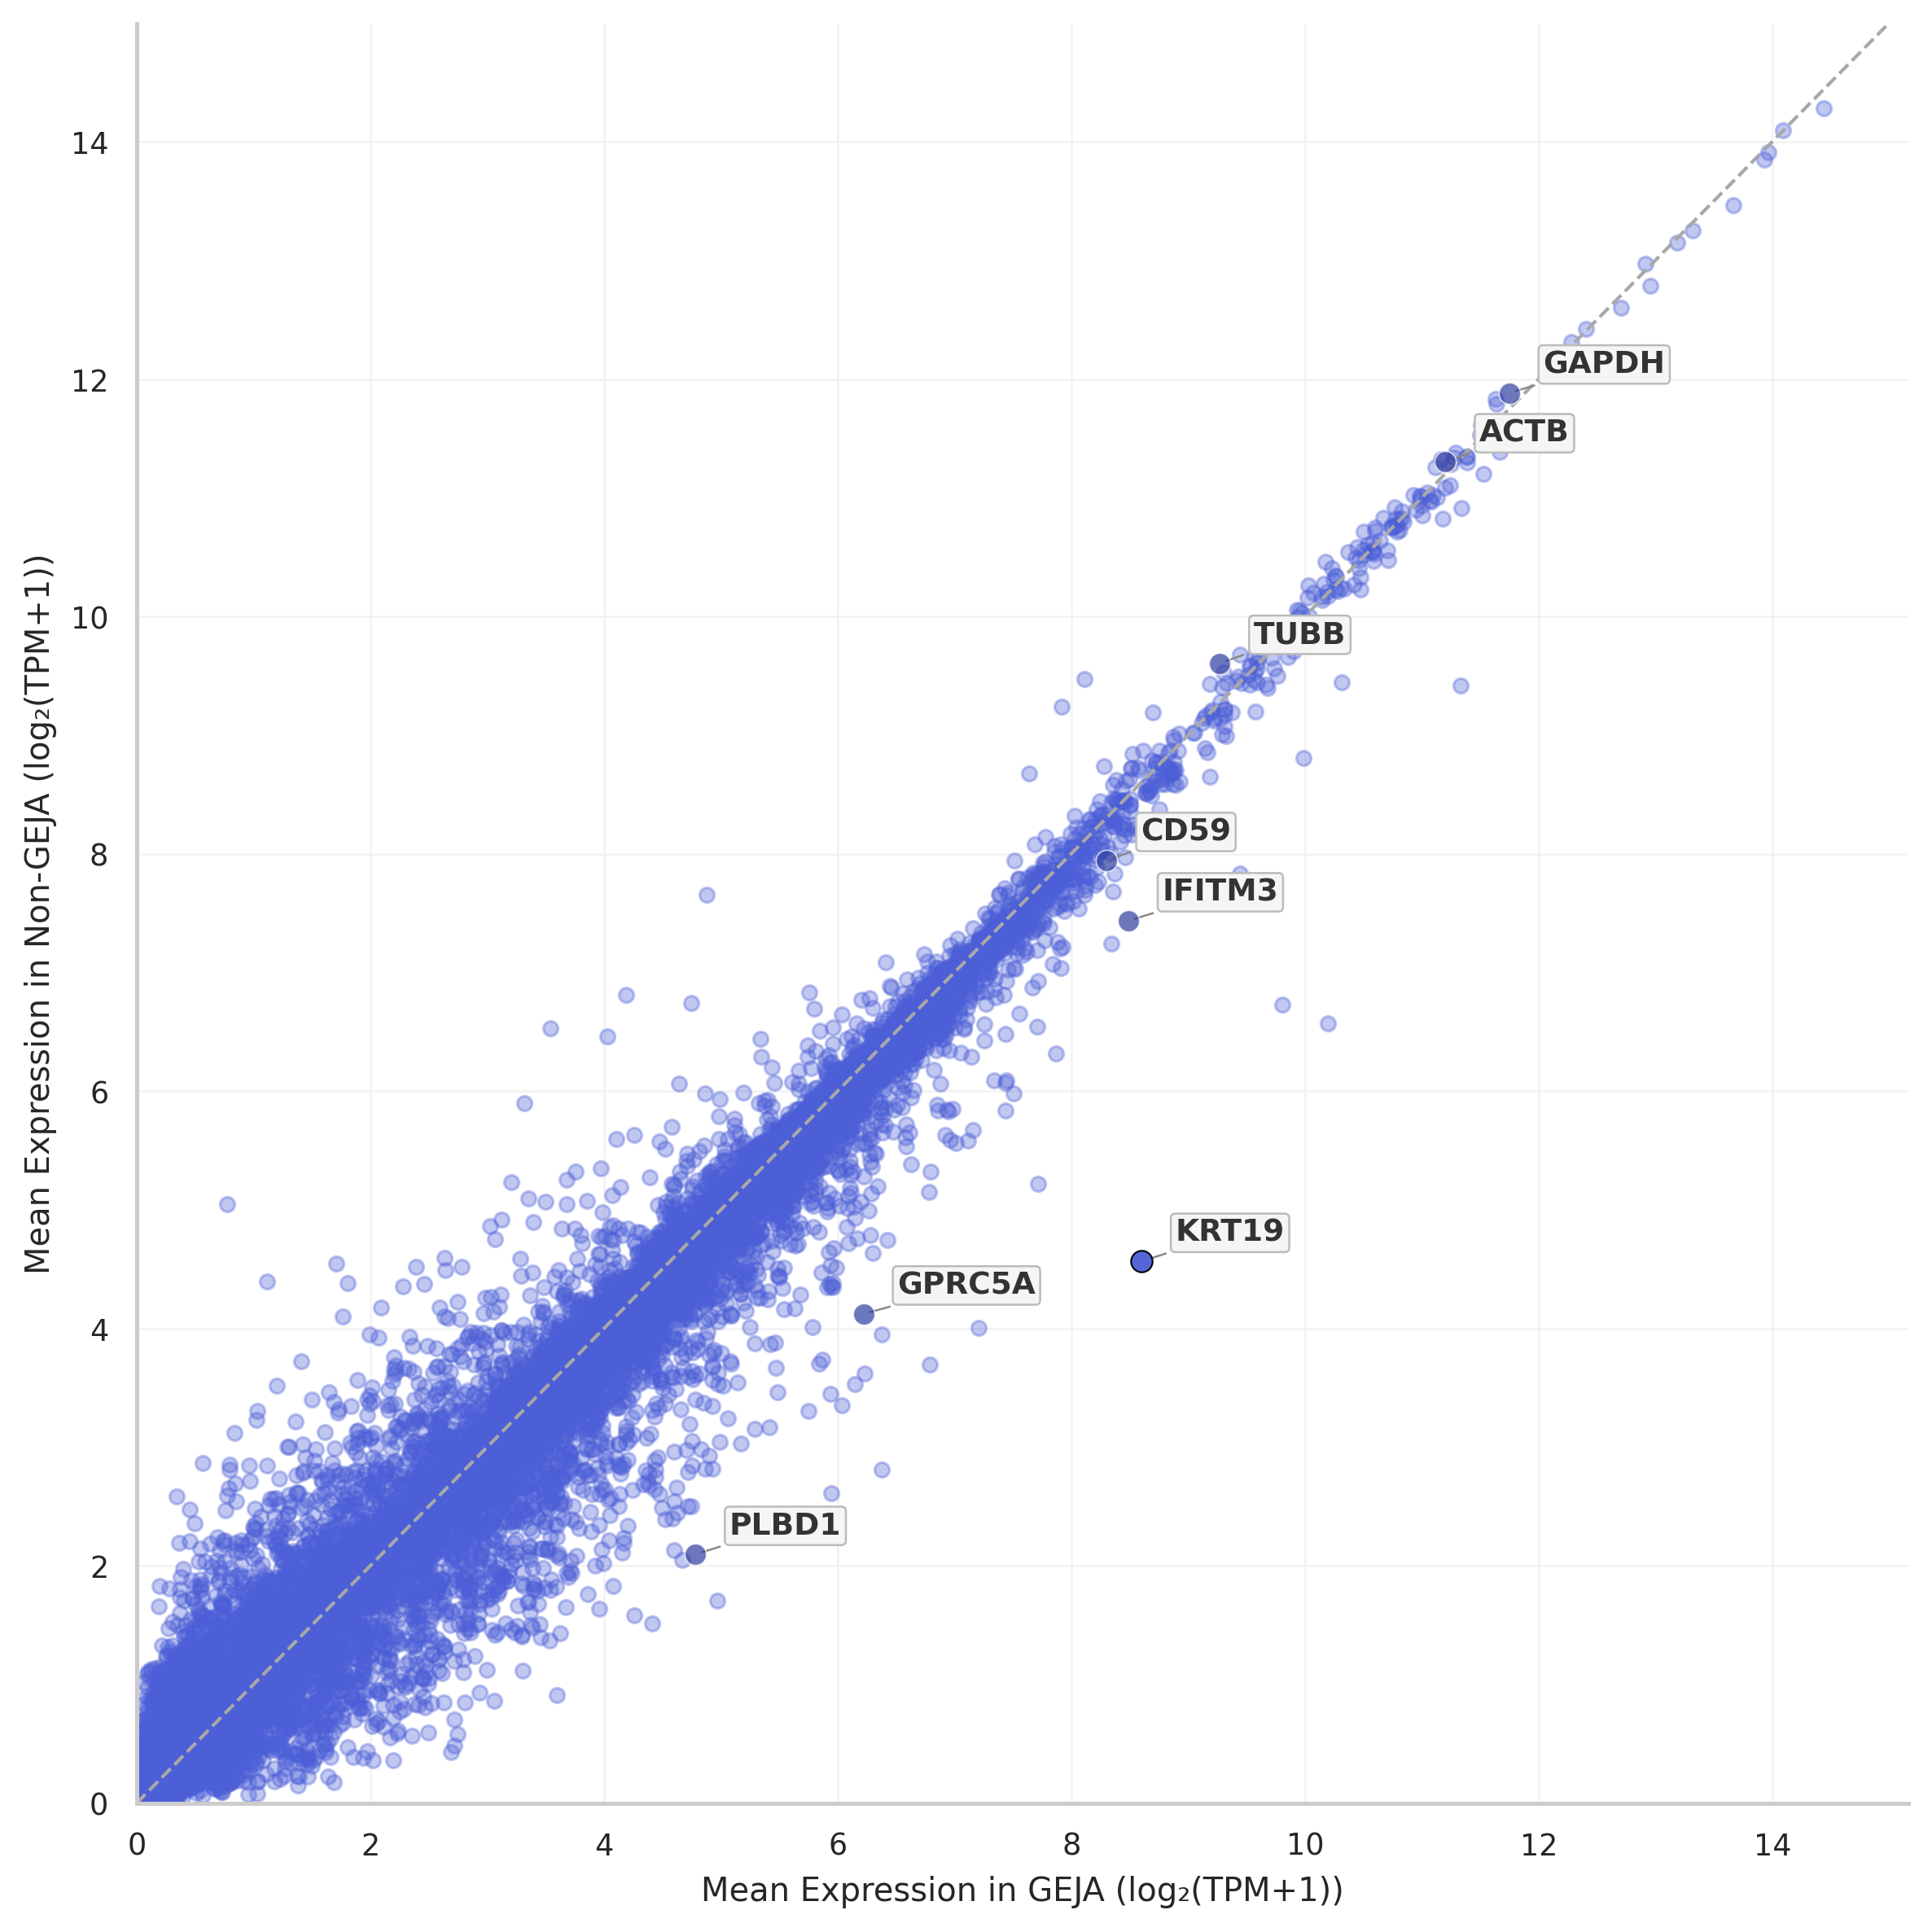

In [ ]:
import matplotlib.pyplot as plt

import seaborn as sns

sns.set_theme(
    style="whitegrid",
    context="paper"
)

highlight_genes = ["PLBD1", "GPRC5A", "IFITM3", "CD59", "TUBB", "ACTB", "GAPDH"]

plt.figure(figsize=(8,8), dpi=300)

# Find KRT19

highlight = df[df["Gene"].isin(highlight_genes)]
others = df[~df["Gene"].isin(highlight_genes)]
krt = df[df["Gene"] == "KRT19"]


plt.scatter(
    others["GEJA"],
    others["Not_GEJA"],
    s=75,
    color="#4C5FD7",
    alpha=0.35,
    rasterized=True,
    marker="."
)

plt.scatter(
    highlight["GEJA"],
    highlight["Not_GEJA"],
    s=40,
    color="#2F3E9E",
    alpha=0.7,
    edgecolors="white",
    linewidths=0.4,
    zorder=4
)

plt.scatter(
    krt["GEJA"],
    krt["Not_GEJA"],
    s=40,
    color="#5666D6",
    edgecolors="black",
    linewidths=0.5,
    zorder=5,
    rasterized=True,
)

# Add label
plt.annotate(
    "KRT19",
    xy=(krt["GEJA"].iloc[0], krt["Not_GEJA"].iloc[0]),
    xytext=(10, 6),
    textcoords="offset points",
    fontsize=9,
    fontweight="bold",
    color="#333333",
    arrowprops=dict(
        arrowstyle="-",
        color="#888888",
        lw=0.6
    ),
    bbox=dict(
      boxstyle="round,pad=0.15",
      fc="#F5F5F5",
      ec="#BBBBBB",
      lw=0.6
  )
)

for _, row in highlight.iterrows():
    plt.annotate(
        row["Gene"],
        xy=(row["GEJA"], row["Not_GEJA"]),
        xytext=(10, 6),
        textcoords="offset points",
        fontsize=9,
        fontweight="bold",
        color="#333333",
        arrowprops=dict(
            arrowstyle="-",
            color="#888888",
            lw=0.6
        ),
        bbox=dict(
          boxstyle="round,pad=0.15",
          fc="#F5F5F5",
          ec="#BBBBBB",
          lw=0.6
      )
    )

plt.xlabel("Mean Expression in GEJA (log₂(TPM+1))")
plt.ylabel("Mean Expression in Non-GEJA (log₂(TPM+1))")

plt.plot(
    [0,15],
    [0,15],
    color="#A8A8A8",
    linestyle="--",
    linewidth=1
)

ax = plt.gca()

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.grid(
    color="#F2F2F2",
    linewidth=0.6
)

ax.spines["left"].set_linewidth(1.2)
ax.spines["bottom"].set_linewidth(1.2)

plt.xlim(0, df["GEJA"].max() * 1.05)
plt.ylim(0, df["Not_GEJA"].max() * 1.05)

plt.tight_layout()

plt.savefig("Figure4.pdf", bbox_inches="tight")
plt.savefig("Figure4.png", dpi=600, bbox_inches="tight")

plt.show()
ax.margins(x=0, y=0)

In [ ]:
plt.savefig(
    "Figure2.pdf",
    bbox_inches="tight"
)

<Figure size 640x480 with 0 Axes>